# Modelado de proteínas y análisis de variantes
## De la genética clínica al ecosistema: MC1R y el melanismo adaptativo en ratones

**¿Una mutación puede dar una **adaptación** en poblaciones silvestres? como resistencia, camuflaje, tolerancia al frío...**

  Los *ratones de playa* (*Peromyscus polionotus*), pueden presentar **un solo cambio de aminoácido** en el receptor **MC1R** que vuelve su pelaje más claro para camuflarse en arena clara y sobrevivir a los búhos.


### 1. MC1R, melanina y selección natural

- **MC1R** (receptor de melanocortina 1) es un receptor en la membrana de los melanocitos. Cuando se activa, la célula fabrica **eumelanina** (pigmento oscuro); cuando está "apagado", fabrica **feomelanina** (claro/rojizo).
- En *Peromyscus polionotus* de la **costa del Golfo (Florida)**, el alelo claro lleva una mutación que **cambia**: **Arginina (Arg) → Cisteína (Cys)**.
- Ese pelaje claro **camufla** al ratón sobre la arena blanca de las dunas → menos depredación por búhos y rapaces → la mutación **es seleccionada**. Explica ~10–36 % de la variación de color (Hoekstra et al., 2006, *Science*).

> La literatura nombra la mutación **"R65C"**; en la secuencia cae en la **posición 67**.


## 2. Instalación de dependencias

In [3]:
# Librerías de Python
!pip -q install py3Dmol biopython requests matplotlib pandas
#  py3Dmol  -> ver proteínas en 3D dentro del notebook
#  biopython-> herramientas de estructuras y secuencias
#  requests -> descargar archivos de internet
#  matplotlib -> análisis de datos y creación de gráficos 2D y 3D
#  pandas -> manipulación, limpieza y análisis de datos
print("Entorno preparado correctamente")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 14.3 MB/s eta 0:00:00
Entorno preparado correctamente


## 3. Modelar la proteína

Como no siempre existe una estructura experimental de *nuestra* especie, la **predecimos** a partir de la secuencia de aminoácidos. Usaremos **ColabFold** (la versión rápida de AlphaFold).

**Pasos:**
1. Abre ColabFold → [AlphaFold2 en Colab](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb)
2. Pega la secuencia del **alelo ancestral (oscuro)** del MC1R del ratón de playa:

```
MPTQGPQKRLLGSLNSTSTATPHLGLATNQTGPWCLQVSIPDGLFLSLGLVSLVENVLVVIAITKNRNLHSPMYSFICCLALSDLMVSISLVLETAIILLLEAGALVTRAALVQQLDNVIDVLICGSMVSSLCFLGVIAIDRYISIFYALRYHSIVTLPRARRAIVGIWVASIFFSTLFITYYNHTAVLICLVTFFLAMLALMAILYVHMLTRAYQHAQGIAQLQKRQGSTRQGFCLKGAATLTIILGIFFLCWGPFFLHLTLIVLCPQHPTCSCIFKNFNLYLVLIIFSSIVDPLIYAFRSQELRMTLREVLLCSW
```

3. Ejecuta, descarga el `.pdb` y súbelo a este Colab con el nombre **`MC1R_raton.pdb`**.

In [4]:
import os, requests

def descargar(url, destino):
    r = requests.get(url, headers={"User-Agent":"Mozilla/5.0"}, timeout=120)
    r.raise_for_status()
    open(destino, "wb").write(r.content)
    print(f"✓ {destino}  ({len(r.content)//1024} KB)")

# Modelo AlphaFold de respaldo (MC1R humano Q01726) - descarga confiable
if not os.path.exists("MC1R_AF.pdb"):
    url_af = requests.get("https://alphafold.ebi.ac.uk/api/prediction/Q01726",
                          timeout=60).json()[0]["pdbUrl"]
    descargar(url_af, "MC1R_AF.pdb")

# Estructura EXPERIMENTAL real del MC1R (cryo-EM 7F4D) - para comparar, como el 3LCT de la clase de VUS
if not os.path.exists("MC1R_7F4D.pdb"):
    descargar("https://files.rcsb.org/download/7F4D.pdb", "MC1R_7F4D.pdb")

# Si subiste tu modelo del ratón (ColabFold), se usa ese; si no, el de respaldo
MODELO = "MC1R_raton.pdb" if os.path.exists("MC1R_raton.pdb") else "MC1R_AF.pdb"
print("\nModelo de trabajo:", MODELO)


✓ MC1R_AF.pdb  (198 KB)
✓ MC1R_7F4D.pdb  (725 KB)

Modelo de trabajo: MC1R_raton.pdb


## 4. Evaluar la calidad del modelo (pLDDT)

Evaluamos la calidad con SAVES, un modelo de AlphaFold trae su **propio puntaje de confianza, el pLDDT**, guardado en la columna de *factor B* de cada átomo:

| pLDDT | Confianza |
|---|---|
| ≥ 90 | muy alta |
| 70–90 | buena |
| 50–70 | dudosa |
| < 50 | no interpretable |

Graficamos el pLDDT a lo largo de la proteína: las zonas bajas suelen ser *loops* o extremos flexibles.

[Link a SAVES](https://saves.mbi.ucla.edu/)


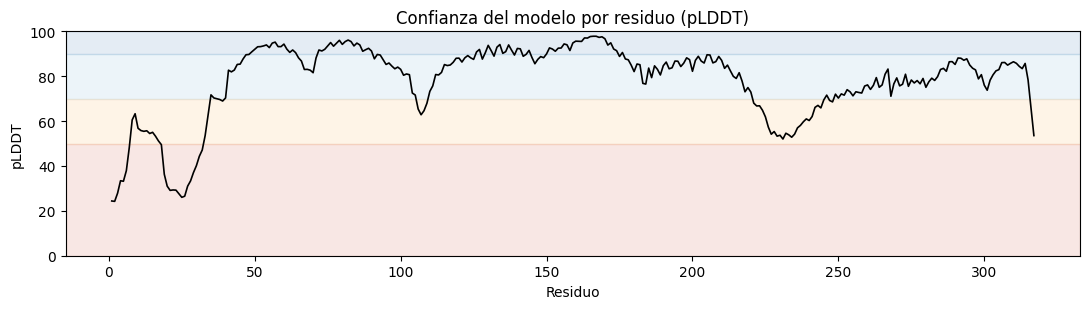

pLDDT promedio: 78.2  (n = 317 residuos)


In [5]:
import matplotlib.pyplot as plt

res, plddt = [], []
for line in open(MODELO):
    if line.startswith("ATOM") and line[12:16].strip() == "CA":
        res.append(int(line[22:26]))
        plddt.append(float(line[60:66]))   # factor B = pLDDT en modelos AlphaFold

plt.figure(figsize=(11, 3.2))
plt.axhspan(90,100, color="#2166ac", alpha=.12)
plt.axhspan(70, 90, color="#67a9cf", alpha=.12)
plt.axhspan(50, 70, color="#fdb863", alpha=.15)
plt.axhspan(0,  50, color="#d6604d", alpha=.15)
plt.plot(res, plddt, color="black", lw=1.2)
plt.xlabel("Residuo"); plt.ylabel("pLDDT"); plt.ylim(0,100)
plt.title("Confianza del modelo por residuo (pLDDT)")
plt.tight_layout(); plt.show()

print(f"pLDDT promedio: {sum(plddt)/len(plddt):.1f}  (n = {len(plddt)} residuos)")


### 4.1 Ver el modelo en 3D, coloreado por confianza

In [6]:
import py3Dmol

v = py3Dmol.view(width=820, height=520)
v.addModel(open(MODELO).read(), "pdb")
# Azul = muy confiable, rojo = poco confiable (escala de pLDDT)
v.setStyle({"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb", "min": 50, "max": 100}}})
v.setBackgroundColor("white")
v.zoomTo()
v.show()


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 5. Localizar la mutación adaptativa

La mutación vive en un motivo muy conservado: **...K-N-R-N-L-H...** (inicio de la primera asa intracelular). Buscamos esa arginina en *nuestro* modelo y dejamos que el código nos diga en qué posición cae — para no confiar en un número "de memoria".


In [7]:
aa3to1 = {'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E',
          'GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F',
          'PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'}

seq = {}
for line in open(MODELO):
    if line.startswith("ATOM") and line[12:16].strip() == "CA":
        seq[int(line[22:26])] = aa3to1.get(line[17:20].strip(), "X")

orden = sorted(seq)
s = "".join(seq[i] for i in orden)
i = s.find("KNRNLH")              # motivo conservado
arg_pos = orden[i + 2]            # la R es el 3er residuo del motivo
print(f"Motivo 'KNRNLH' encontrado.")
print(f"Arginina adaptativa -> posición {arg_pos} en ESTE modelo.")
print(f"(En la literatura se le llama 'R65C'; la numeración depende de la secuencia de referencia.)")
print(f"Contexto del motivo: ...{s[i]}{s[i+1]}[{s[i+2]}]{s[i+3]}{s[i+4]}{s[i+5]}...  (la [R] es la que mutaremos)")


Motivo 'KNRNLH' encontrado.
Arginina adaptativa -> posición 67 en ESTE modelo.
(En la literatura se le llama 'R65C'; la numeración depende de la secuencia de referencia.)
Contexto del motivo: ...KN[R]NLH...  (la [R] es la que mutaremos)


### 5.1 Ver la arginina dentro de la proteína

In [8]:
v = py3Dmol.view(width=820, height=520)
v.addModel(open(MODELO).read(), "pdb")
v.setStyle({"cartoon": {"color": "lightgrey"}})
v.addStyle({"resi": str(arg_pos)}, {"stick": {"colorscheme": "greenCarbon"}})
v.addResLabels({"resi": str(arg_pos)}, {"backgroundColor": "black", "fontColor": "white"})
v.setBackgroundColor("white")
v.zoomTo({"resi": str(arg_pos)})
v.show()


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 5.2 ¿Con qué está en contacto la arginina?

La Arg es un aminoácido **grande y con carga positiva**: suele formar puentes salinos / de hidrógeno con vecinos negativos. Al cambiarla por **Cys** (pequeña, sin carga) podríamos **romper** esos contactos. Vecinos a ≤ 5 Å:

In [ ]:
import numpy as np, pandas as pd

def leer_atomos(path):
    A = []
    for line in open(path):
        if line.startswith(("ATOM","HETATM")):
            A.append((line[12:16].strip(), line[17:20].strip(), int(line[22:26]),
                      np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])])))
    return A

AT  = leer_atomos(MODELO)
arg = [a for a in AT if a[2] == arg_pos]

vecinos = {}
for aname, rn, ri, xyz in AT:
    if abs(ri - arg_pos) <= 2:          # excluir vecinos inmediatos en la secuencia
        continue
    d = min(np.linalg.norm(xyz - a[3]) for a in arg)
    if d <= 6.0:
        vecinos[(rn, ri)] = min(vecinos.get((rn, ri), 99), round(float(d), 2))

df = pd.DataFrame([(rn, ri, d) for (rn, ri), d in vecinos.items()],
                  columns=["residuo", "posicion", "dist_min_Å"]).sort_values("dist_min_Å")
print(f"Contactos espaciales (<= 6 Å) de la posición {arg_pos}, sin contar vecinos inmediatos:")
df.reset_index(drop=True)


## 6. Introducir la mutación Arg→Cys (en ChimeraX)

El cambio de aminoácido y el análisis se hacen en **ChimeraX** (interfaz visual, gratis: [download](https://www.cgl.ucsf.edu/chimerax/download.html)). Estos son los comandos:

```text
# Abrir el modelo (ancestral, con Arg)
open MC1R_AF.pdb                 # o tu MC1R_raton.pdb

Comparamos **ancestral (Arg)** vs **mutante (Cys)**:

# Superponer las dos estructuras para ver si cambia la conformación global
open MC1R_AF.pdb                 # #1 ancestral
open MC1R_mutante_Cys67.pdb      # #2 mutante
matchmaker #2 to #1
#  RMSD bajo (~0.5-2 Å) = misma conformación general

# Ver el residuo y marcarlo
select :67                       # usa la posición que detectó el notebook
color sel yellow
style sel stick
label sel

# Hacer el cambio de aminoácido:  Arg -> Cys
swapaa :67 cys

# Guardar el mutante
save MC1R_mutante_Cys67.pdb
```

> En el trabajo real, después se hace una **minimización** (p. ej. en GROMACS) para relajar la estructura antes de medir. Para la clase podemos quedarnos con el *swap* directo y discutirlo.


## 7. Analizar el efecto estructural (ChimeraX)

```
# Choques estéricos (clashes) alrededor del residuo
clashes #1 restrict :62-72 log true
#  Regla práctica: solapamiento > 0.6 Å = choque serio

# Puentes de hidrógeno / salinos del residuo
hbonds #2 restrict :67 reveal true log true   # en el ancestral (Arg)
hbonds #1 restrict :67 reveal true log true   # en el mutante (Cys)

# Medir una distancia concreta a un vecino negativo (ejemplo)
distance #1:67@NH2 #1:68@OD1
distance #1:67@HA #1:68@OD1

distance #2:67@NH2 #2:68@OD1
```

**Umbrales de referencia:**
- Puente H / salino plausible: **2.7–3.3 Å**
- \> 4.0 Å: demasiado lejos, contacto débil

**Lo que esperamos contar:** la Arg ancestral hace contactos (carga +); la Cys los pierde → cambia la *señalización*, aunque la forma global casi no se mueva.


## 8. Predecir el efecto con servidores web (ΔΔG)

Sube el `.pdb` o pega la mutación:

| Servidor | Qué hace | Enlace |
|---|---|---|
| **Missense3D** | ¿el cambio daña la estructura? (sí/no) | http://missense3d.bc.ic.ac.uk/ |
| **DynaMut2** | ΔΔG de estabilidad (machine learning + modos normales) | https://biosig.lab.uq.edu.au/dynamut2/ |

**Cómo leer el ΔΔG:**
- ΔΔG ≈ 0 → la mutación **casi no cambia la estabilidad**
- ΔΔG negativo → (según el programa) estabiliza / desestabiliza — ¡ojo, cada programa usa el signo distinto! Siempre lee la etiqueta ("Stabilising" / "Destabilising").


## 9. Interpretación y cierre

**¿Qué encontramos?:**

La mutación Arg→Cys del MC1R:
-NO cambia la estructura de la proteína
-NO la desestabiliza
-Genera un choque entre Cys67 e His70, perdiendo fuerza de van der Waals

Entonces, esta mutación no afecta la **estabilidad**. Por eso los predictores de ΔΔG (DynaMut2) dicen **ΔΔG ≈ 0**
Sin embargo, en la naturaleza, esa mutación **sí importa**: pues afecta la **señalización** del receptor, disminuyendo la producción de eumelanina, aumentando la de feomelanina y vuelve claro al ratón.


**La herramienta in silico es un indicio, no un veredicto.** La decisión final combina estructura + evolución (¿está conservado? ¿hay firma de selección?) + experimento.

**CONCLUSIÓN**
1. Una mutación puntual puede ser el motor de una adaptación (color, resistencia, tolerancia térmica...).
2. Con bioinformática estructural pueden **ver** y **razonar** ese cambio, sin tocar un solo ratón.
3. Las predicciones tienen **límites**: úsenlas con criterio, combinando líneas de evidencia.

##Información extra - Backup

In [ ]:
### Instalar ChimeraX antes de la clase (gratis, ~150 MB)

ChimeraX funciona en **Windows, macOS y Linux** — no es solo para Linux/Ubuntu.
Página oficial de descarga: https://www.cgl.ucsf.edu/chimerax/download.html
(Elige la versión **"Release"** más reciente para tu sistema.)

**Windows (10/11, 64-bit):**
1. Descarga el instalador `.exe` de la sección *Windows*.
2. Doble clic → "Siguiente" → acepta los valores por defecto → "Finalizar".
3. Ábrelo desde el menú Inicio. (Si Windows muestra un aviso de "editor desconocido",
   clic en "Más información" → "Ejecutar de todas formas".)

**macOS (Intel o Apple Silicon):**
1. Descarga el `.dmg` correspondiente a tu Mac.
2. Arrástralo a la carpeta *Aplicaciones*.
3. Primera vez: si aparece un aviso de seguridad, ve a
   *Ajustes del sistema → Privacidad y seguridad → Abrir de todos modos*.

**Requisitos:** cualquier laptop de los últimos ~8 años sirve (incluso gráficos Intel
integrados) y ~1 GB de disco libre.

**Importante:** instálenlo **antes** de la clase (no en vivo) y traigan los archivos
`MC1R_raton.pdb` y `MC1R_mutante_Cys67.pdb` que les compartiré.
Los comandos de ChimeraX son idénticos en Windows, Mac y Linux.

In [ ]:
## 6-bis. Plan B sin ChimeraX (todo en el navegador)

Si alguien no pudo instalar ChimeraX, puede **ver y comparar** la proteína ancestral (Arg)
y la mutante (Cys) aquí mismo, en el navegador, con py3Dmol — sin instalar nada.

> El archivo del mutante (`MC1R_mutante_Cys67.pdb`) se genera una sola vez (en ChimeraX,
> o con la celda opcional de PyMOL de abajo) y se comparte con el grupo.

In [9]:
import os, py3Dmol

WT  = "MC1R_raton.pdb"            # ancestral (Arg67)
MUT = "MC1R_mutante_Cys67.pdb"    # mutante  (Cys67)

assert os.path.exists(WT) and os.path.exists(MUT), \
    "Sube MC1R_raton.pdb y MC1R_mutante_Cys67.pdb (te los comparte la profesora)."

v = py3Dmol.view(width=850, height=550)
v.addModel(open(WT).read(),  "pdb")   # modelo 0 = ancestral
v.addModel(open(MUT).read(), "pdb")   # modelo 1 = mutante

# Estructura global en gris (solo una vez; los esqueletos coinciden)
v.setStyle({"model": 0}, {"cartoon": {"color": "lightgrey"}})

# Cadenas laterales del residuo 67: Arg (verde) vs Cys (naranja), superpuestas
v.addStyle({"model": 0, "resi": "67"}, {"stick": {"colorscheme": "greenCarbon",  "radius": 0.25}})
v.addStyle({"model": 1, "resi": "67"}, {"stick": {"colorscheme": "orangeCarbon", "radius": 0.25}})
v.addResLabels({"model": 0, "resi": "67"}, {"backgroundColor": "black", "fontColor": "white"})

v.setBackgroundColor("white")
v.zoomTo({"resi": "67"})
v.show()
print("Verde = Arg67 (ancestral, grande y con carga +)   |   Naranja = Cys67 (mutante, pequeña y neutra)")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Verde = Arg67 (ancestral, grande y con carga +)   |   Naranja = Cys67 (mutante, pequeña y neutra)


In [10]:
import numpy as np, pandas as pd

def leer_atomos(path):
    A = []
    for line in open(path):
        if line.startswith(("ATOM", "HETATM")):
            A.append((line[17:20].strip(), int(line[22:26]),
                      np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])])))
    return A

def contactos_de_67(path, cutoff=6.0):
    AT  = leer_atomos(path)
    res = [a for a in AT if a[1] == 67]
    out = {}
    for rn, ri, xyz in AT:
        if abs(ri - 67) <= 2:                      # salta vecinos inmediatos en secuencia
            continue
        d = min(np.linalg.norm(xyz - a[2]) for a in res)
        if d <= cutoff:
            out[(rn, ri)] = min(out.get((rn, ri), 99), round(float(d), 2))
    return out

wt  = contactos_de_67("MC1R_raton.pdb")
mut = contactos_de_67("MC1R_mutante_Cys67.pdb")

print(f"Contactos (<=6 Å) de la posición 67 —  Arg (ancestral): {len(wt)}   |   Cys (mutante): {len(mut)}")
filas = []
for k in sorted(set(wt) | set(mut), key=lambda x: x[1]):
    filas.append((f"{k[0]}{k[1]}", wt.get(k, "—"), mut.get(k, "—")))
pd.DataFrame(filas, columns=["vecino", "dist_Arg (Å)", "dist_Cys (Å)"])

Contactos (<=6 Å) de la posición 67 —  Arg (ancestral): 3   |   Cys (mutante): 3


,vecino,dist_Arg (Å),dist_Cys (Å)
0,ILE63,5.25,5.25
1,THR64,4.97,5.33
2,HIS70,2.92,2.92


In [11]:
# Opcional: crear MC1R_mutante_Cys67.pdb en el navegador, sin ChimeraX.
# Si la instalación falla, simplemente usen el archivo que les compartió la profesora.
try:
    import pymol
except ImportError:
    !pip -q install pymol-open-source
from pymol import cmd

cmd.load("MC1R_raton.pdb", "obj")
cmd.wizard("mutagenesis")
cmd.refresh_wizard()
cmd.get_wizard().set_mode("CYS")      # aminoácido nuevo
cmd.get_wizard().do_select("resi 67") # posición a mutar
cmd.get_wizard().apply()
cmd.set_wizard()
cmd.save("MC1R_mutante_Cys67.pdb", "obj")
print("✓ Mutante generado: MC1R_mutante_Cys67.pdb")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 13.8 MB/s eta 0:00:00
Selected!
 Mutagenesis: 3 rotamers loaded.
 Rotamer 1/3, strain=19.96
✓ Mutante generado: MC1R_mutante_Cys67.pdb
